In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
DATA_DIR = Path(".")           # папка с csv-файлами
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 100

## 1. Загрузка данных

Файлы разделены точкой с запятой (`;`). Белое вино загружаем только для справки — задание касается красного.

In [2]:
red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
names = (DATA_DIR / "winequality.names").read_text(encoding="utf-8")
print(names[names.find("7. Attribute"):names.find("8. Missing")].strip(), "\n")
print(f"Красное вино: {red.shape[0]} строк, {red.shape[1]} столбцов")
print(f"Белое вино:   {white.shape[0]} строк, {white.shape[1]} столбцов (не используется)")
red.head()

7. Attribute information:

   For more information, read [Cortez et al., 2009].

   Input variables (based on physicochemical tests):
   1 - fixed acidity
   2 - volatile acidity
   3 - citric acid
   4 - residual sugar
   5 - chlorides
   6 - free sulfur dioxide
   7 - total sulfur dioxide
   8 - density
   9 - pH
   10 - sulphates
   11 - alcohol
   Output variable (based on sensory data): 
   12 - quality (score between 0 and 10) 

Красное вино: 1599 строк, 12 столбцов
Белое вино:   4898 строк, 12 столбцов (не используется)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


In [3]:
red.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## 2. Исследование данных

### 2.1 Пропуски, дубликаты, описательная статистика

In [4]:
print("Пропусков всего:", red.isna().sum().sum())
print("Полных дубликатов строк:", red.duplicated().sum())
red.describe().T

Пропусков всего: 0
Полных дубликатов строк: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


### 2.2 Распределение целевой оценки `quality`

Классы сильно несбалансированы: почти все вина имеют оценку 5–6, крайних (3, 4, 8) очень мало.

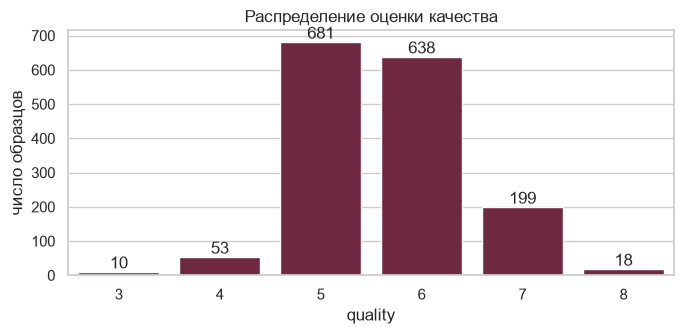

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
counts = red["quality"].value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, color="#7a1f3d", ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center")
ax.set(xlabel="quality", ylabel="число образцов", title="Распределение оценки качества")
plt.tight_layout(); plt.show()

### 2.3 Распределения признаков

Многие признаки скошены вправо (`residual sugar`, `chlorides`, `sulphates`, `total sulfur dioxide`) — это признак наличия выбросов.

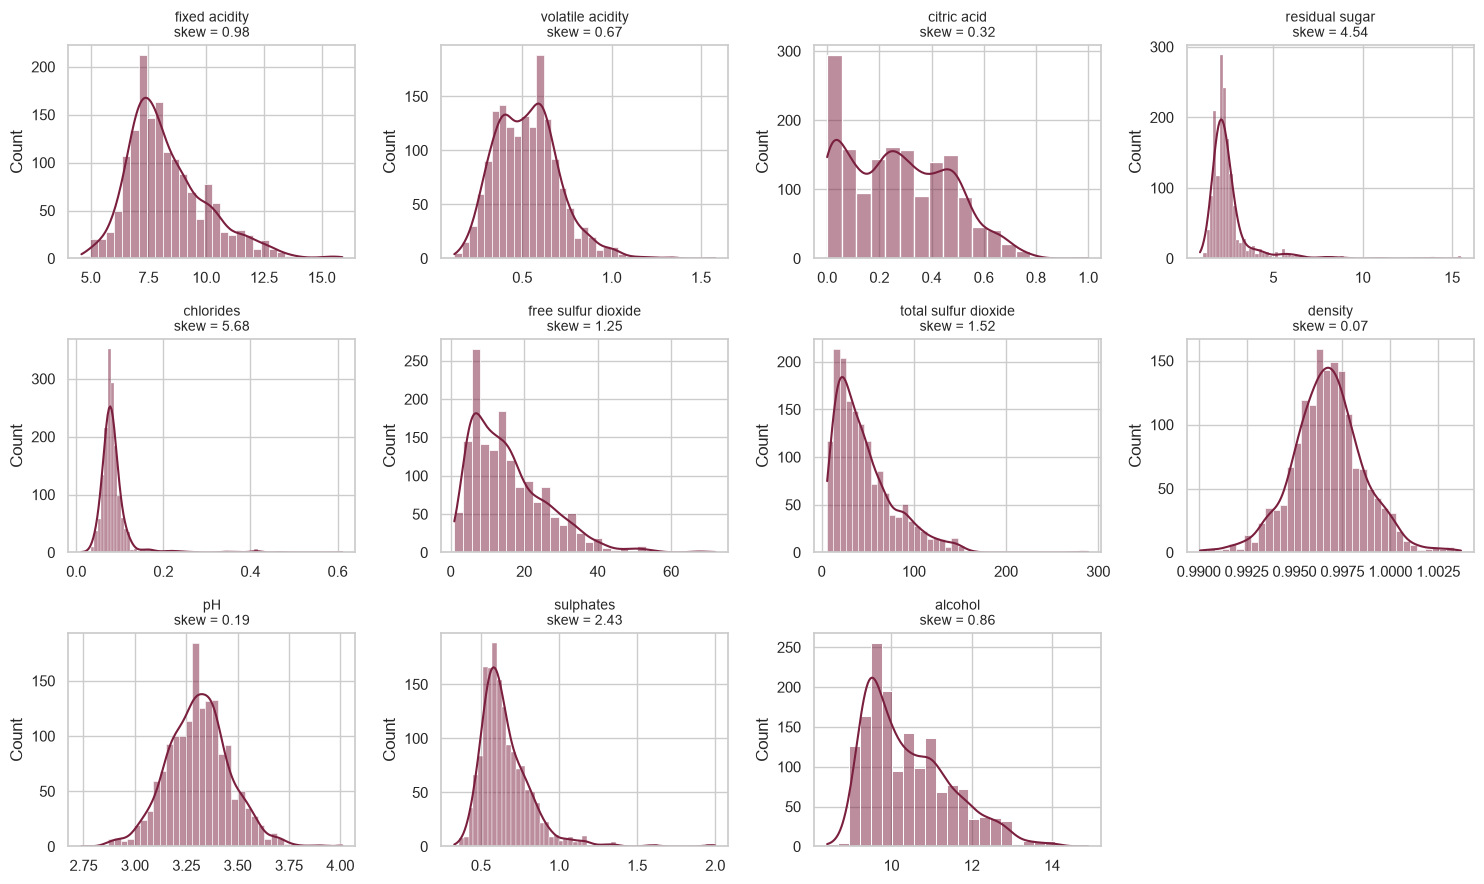

In [6]:
features_all = red.columns.drop("quality")
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), features_all):
    sns.histplot(red[col], kde=True, ax=ax, color="#7a1f3d")
    ax.set_title(f"{col}\nskew = {red[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

### 2.4 Корреляции

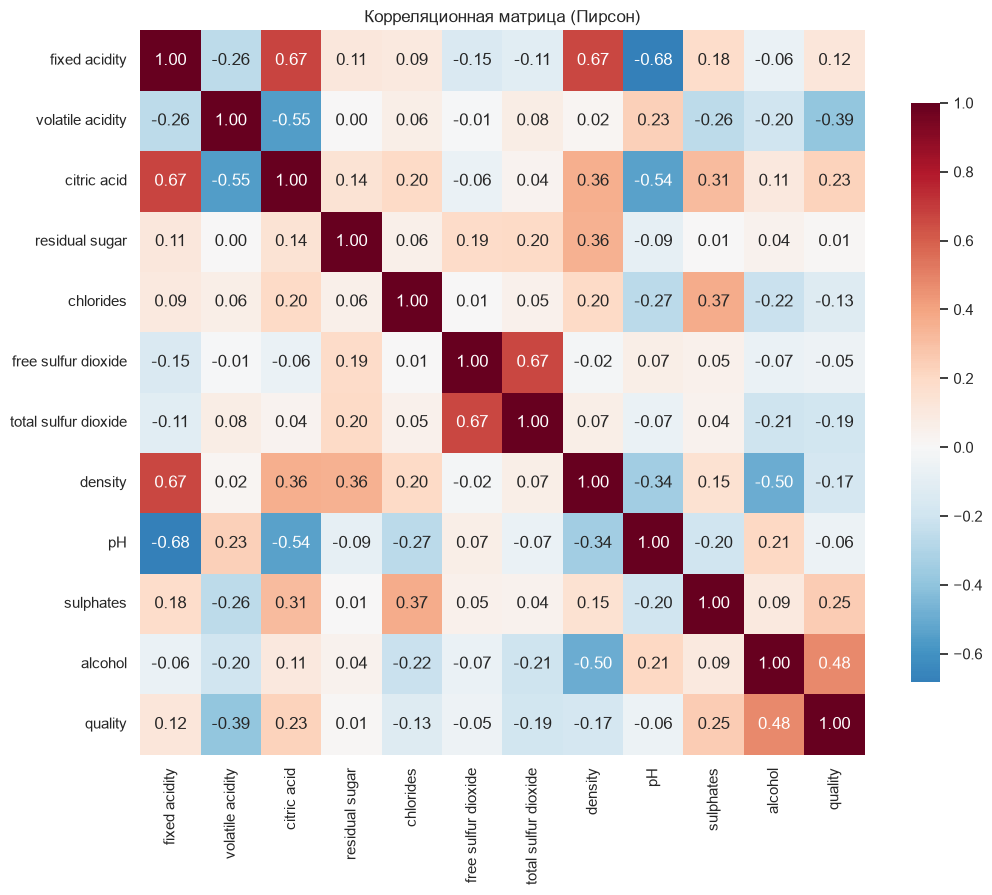

In [7]:
corr = red.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Корреляционная матрица (Пирсон)")
plt.tight_layout(); plt.show()

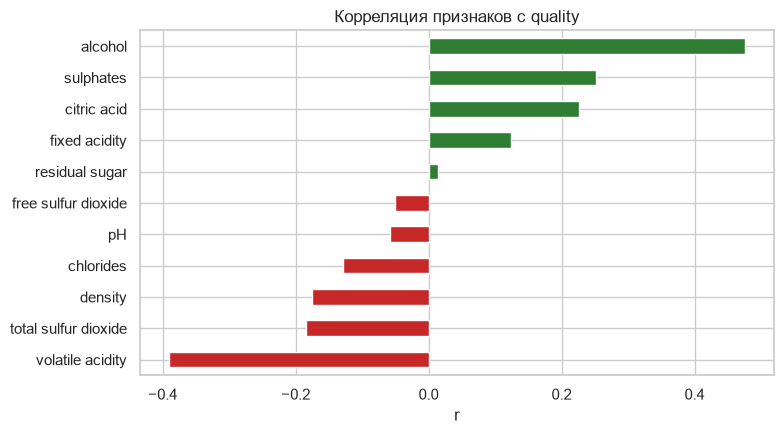

,r с quality
alcohol,0.476
volatile acidity,-0.391
sulphates,0.251
citric acid,0.226
total sulfur dioxide,-0.185
density,-0.175
chlorides,-0.129
fixed acidity,0.124
pH,-0.058
free sulfur dioxide,-0.051


In [8]:
q_corr = corr["quality"].drop("quality").sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
q_corr.plot.barh(color=np.where(q_corr > 0, "#2e7d32", "#c62828"), ax=ax)
ax.set(title="Корреляция признаков с quality", xlabel="r")
plt.tight_layout(); plt.show()
q_corr.to_frame("r с quality").sort_values("r с quality", key=abs, ascending=False)

### 2.5 Выбросы (правило 1.5·IQR)

In [9]:
def iqr_outlier_mask(frame, cols, k=1.5):
    q1, q3 = frame[cols].quantile(.25), frame[cols].quantile(.75)
    iqr = q3 - q1
    return (frame[cols] < q1 - k * iqr) | (frame[cols] > q3 + k * iqr)

out = iqr_outlier_mask(red, list(features_all))
pd.DataFrame({"выбросов": out.sum(), "доля, %": (out.mean() * 100).round(1)}).sort_values("выбросов", ascending=False)

,выбросов,"доля, %"
residual sugar,155,9.7
chlorides,112,7.0
sulphates,59,3.7
total sulfur dioxide,55,3.4
fixed acidity,49,3.1
density,45,2.8
pH,35,2.2
free sulfur dioxide,30,1.9
volatile acidity,19,1.2
alcohol,13,0.8


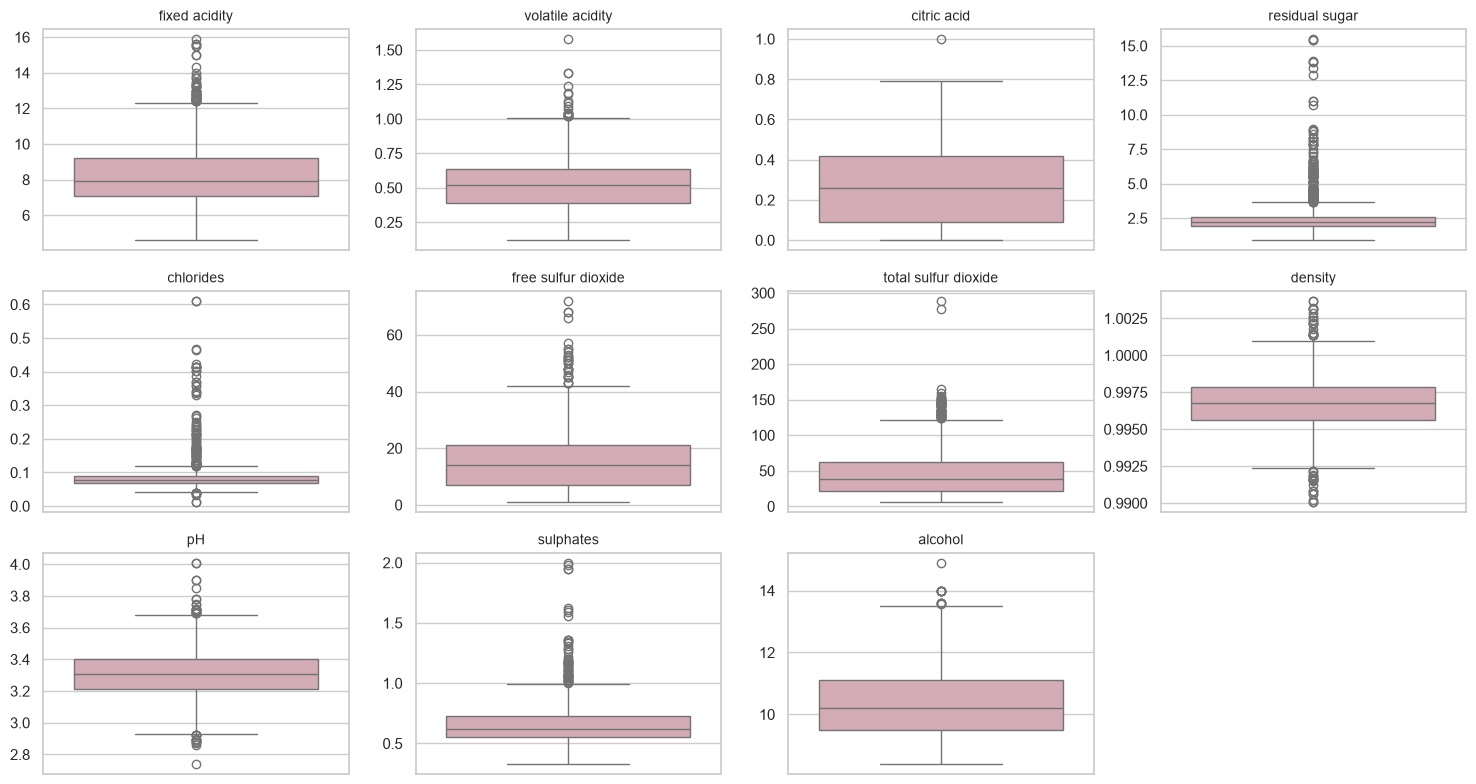

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, col in zip(axes.ravel(), features_all):
    sns.boxplot(y=red[col], ax=ax, color="#d9a5b3")
    ax.set_title(col, fontsize=10); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

**Выводы по исследованию**

* Пропусков нет, но есть 240 полных дубликатов строк — их удалим, чтобы они не создавали искусственные «сгущения» точек.
* Признаки в разных шкалах (от 0.01 у `chlorides` до ~100 у `total sulfur dioxide`) → нужно масштабирование.
* Сильнее всего с качеством связаны: `alcohol` (r ≈ +0.48), `volatile acidity` (r ≈ −0.39), `sulphates` (r ≈ +0.25).
* Есть сильно коррелирующие между собой признаки (`fixed acidity`–`citric acid`–`density`–`pH`, `free`–`total sulfur dioxide`), что подтверждает замечание в описании набора о целесообразности отбора признаков.

## 3. Выбор трёх признаков и предобработка

### 3.1 Какие три признака

Берём **`alcohol`, `volatile acidity`, `sulphates`**:

* это три признака с наибольшей по модулю корреляцией с `quality` — сегменты по ним будут содержательно интерпретируемы с точки зрения качества;
* между собой они почти не коррелируют (|r| ≤ 0.26), т.е. несут разную информацию и не дублируют друг друга;
* все три — понятные технологу характеристики: крепость, «уксусность» (летучие кислоты) и содержание сульфатов (консервант, влияет на вкус).

In [11]:
FEATURES = ["alcohol", "volatile acidity", "sulphates"]
red[FEATURES].corr()

,alcohol,volatile acidity,sulphates
alcohol,1.000,-0.202,0.094
volatile acidity,-0.202,1.000,-0.261
sulphates,0.094,-0.261,1.000


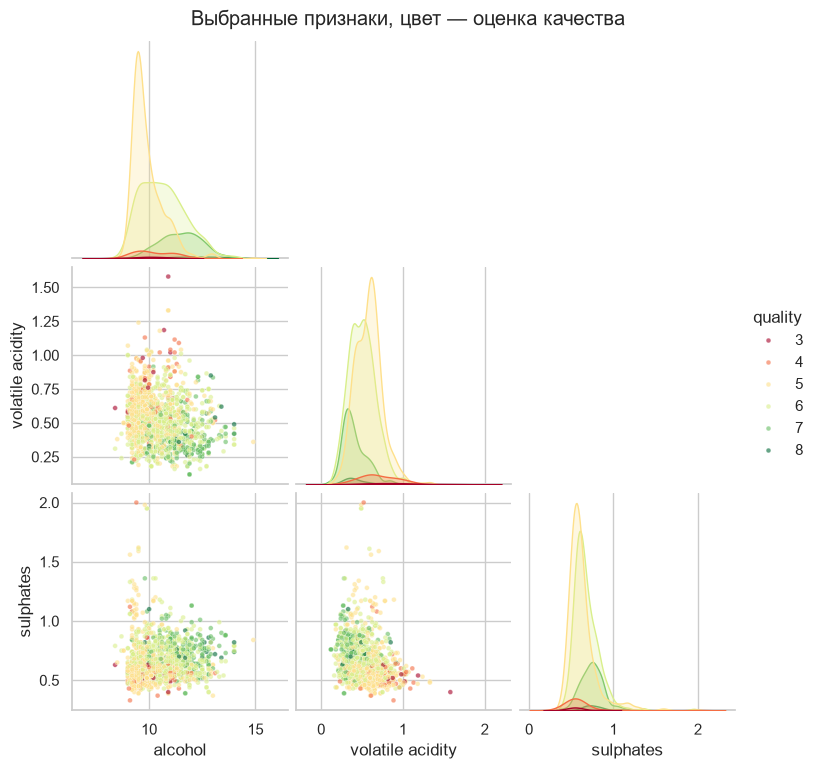

In [12]:
g = sns.pairplot(red[FEATURES + ["quality"]], hue="quality", palette="RdYlGn",
                 plot_kws={"s": 12, "alpha": .6}, corner=True)
g.figure.suptitle("Выбранные признаки, цвет — оценка качества", y=1.02)
plt.show()

### 3.2 Удаление дубликатов и выбросов

Выбросы удаляем по правилу 1.5·IQR **только по трём выбранным признакам**.
Это важно для K-Means и иерархической кластеризации (Ward): квадратичная функция потерь заставляет их выделять отдельный кластер под несколько экстремальных точек. Особенно это касается `sulphates` (асимметрия ≈ 2.4).

In [13]:
df = red.drop_duplicates().reset_index(drop=True)
print(f"После удаления дубликатов: {len(df)}")

mask = iqr_outlier_mask(df, FEATURES).any(axis=1)
print(f"Выбросов по трём признакам: {mask.sum()} ({mask.mean():.1%})")
df = df.loc[~mask].reset_index(drop=True)
print(f"Итоговый объём выборки: {len(df)}")

После удаления дубликатов: 1359
Выбросов по трём признакам: 86 (6.3%)
Итоговый объём выборки: 1273


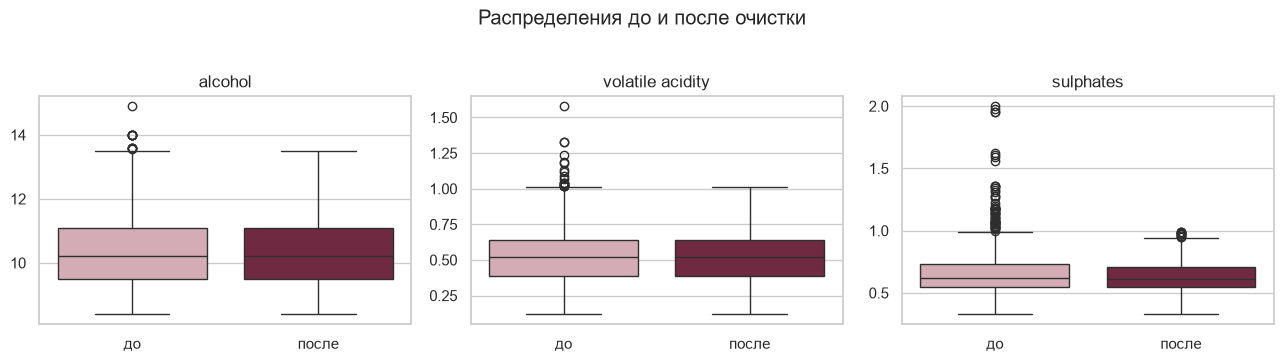

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=pd.DataFrame({"до": red[col], "после": df[col]}).melt(),
                x="variable", y="value", ax=ax, palette=["#d9a5b3", "#7a1f3d"])
    ax.set(title=col, xlabel="", ylabel="")
plt.suptitle("Распределения до и после очистки", y=1.03)
plt.tight_layout(); plt.show()

### 3.3 Масштабирование

Все три метода опираются на евклидово расстояние, поэтому признаки приводим к нулевому среднему и единичному стандартному отклонению (`StandardScaler`). Без этого кластеризация определялась бы признаком с наибольшим разбросом.

In [15]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
pd.DataFrame(X, columns=FEATURES).describe().loc[["mean", "std", "min", "max"]]

,alcohol,volatile acidity,sulphates
mean,-8.931e-17,4.633e-16,-3.461e-16
std,1.000e+00,1.000e+00,1.000e+00
min,-1.941e+00,-2.391e+00,-2.572e+00
max,2.954e+00,2.878e+00,2.986e+00


## 4. Выбор методов кластеризации

| Метод | Тип | Почему подходит | Перебираемые параметры |
|---|---|---|---|
| **K-Means** | итеративный | Быстрый, хорошо работает на масштабированных непрерывных признаках, даёт компактные «центроидные» сегменты, которые легко описать средними значениями. | `n_clusters` = 2…10, `init` = k-means++ / random |
| **Agglomerative** | иерархический | Не требует случайной инициализации, даёт дендрограмму — видно, на каком уровне объединяются группы. Разные способы связи дают разную форму кластеров. | `linkage` = ward / complete / average / single, `n_clusters` = 2…8 |
| **DBSCAN** | плотностной | Находит кластеры произвольной формы, не требует задавать число кластеров, сам выделяет шум. Проверяет, есть ли в данных действительно разделённые по плотности группы. | `eps` (по графику k-расстояний), `min_samples` = 5…25 |

## 5. Выбор метрики качества

Истинных меток кластеров нет (`quality` — это оценка дегустаторов, а не «правильная» сегментация по химии), поэтому для **выбора модели** нужна **внутренняя** метрика.

**Основная метрика — коэффициент силуэта (Silhouette)**:

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),\,b(i))},$$

где $a(i)$ — среднее расстояние до точек своего кластера, $b(i)$ — до ближайшего чужого.

* одинаково применим ко всем трём методам (в отличие от инерции K-Means);
* учитывает и компактность, и разделённость;
* ограничен диапазоном [−1, 1] и легко интерпретируется.

**Вспомогательные:** индекс Дэвиса–Болдина (меньше — лучше) и Калински–Харабаза (больше — лучше).

**Ограничения корректности.** Силуэт можно «обмануть» вырожденным разбиением (одна точка в отдельном кластере), а у DBSCAN — объявив большую часть точек шумом. Поэтому разбиение считается допустимым, если:
* кластеров ≥ 2;
* самый маленький кластер содержит ≥ 5 % объектов;
* доля шума (DBSCAN) ≤ 15 %.

Для DBSCAN метрики считаются по точкам без шума.

**Для итоговой интерпретации** дополнительно используются внешние метрики ARI и NMI относительно `quality`.

In [16]:
MIN_CLUSTER_SHARE = 0.05
MAX_NOISE_SHARE = 0.15

def evaluate(method, params, labels, X=X):
    labels = np.asarray(labels)
    noise = labels == -1
    core = ~noise
    n_clusters = len(set(labels[core]))
    row = {"method": method, "params": params, "n_clusters": n_clusters,
           "noise_share": noise.mean(), "min_cluster_share": np.nan,
           "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    if n_clusters >= 2:
        sizes = np.bincount(labels[core])
        sizes = sizes[sizes > 0]
        row["min_cluster_share"] = sizes.min() / len(labels)
        row["silhouette"] = silhouette_score(X[core], labels[core])
        row["davies_bouldin"] = davies_bouldin_score(X[core], labels[core])
        row["calinski_harabasz"] = calinski_harabasz_score(X[core], labels[core])
    row["valid"] = (n_clusters >= 2
                    and row["min_cluster_share"] >= MIN_CLUSTER_SHARE
                    and row["noise_share"] <= MAX_NOISE_SHARE)
    return row

results = []

## 6. Обучение моделей с разными параметрами

### 6.1 K-Means

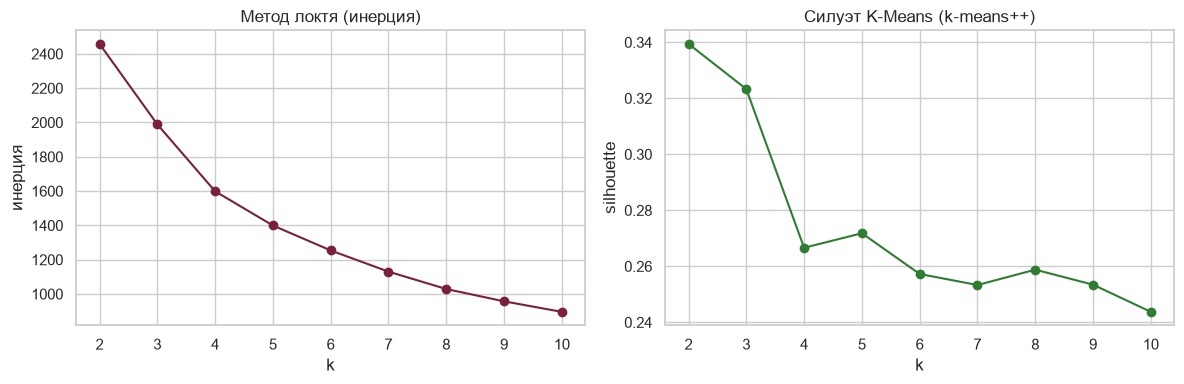

,params,n_clusters,noise_share,min_cluster_share,silhouette,davies_bouldin,calinski_harabasz,valid
0,"k=2, init=k-means++",2,0.0,0.405,0.339,1.220,703.609,True
1,"k=3, init=k-means++",3,0.0,0.219,0.323,1.204,584.246,True
2,"k=4, init=k-means++",4,0.0,0.197,0.267,1.201,587.425,True
3,"k=5, init=k-means++",5,0.0,0.125,0.272,1.125,548.128,True
4,"k=6, init=k-means++",6,0.0,0.123,0.257,1.160,518.401,True
5,"k=7, init=k-means++",7,0.0,0.091,0.253,1.177,501.931,True
6,"k=8, init=k-means++",8,0.0,0.083,0.259,1.111,490.023,True
7,"k=9, init=k-means++",9,0.0,0.066,0.253,1.091,472.421,True
8,"k=10, init=k-means++",10,0.0,0.057,0.244,1.096,457.976,True
9,"k=2, init=random",2,0.0,0.405,0.339,1.220,703.609,True


In [17]:
inertia = {}
for init in ["k-means++", "random"]:
    for k in range(2, 11):
        km = KMeans(n_clusters=k, init=init, n_init=10, random_state=RANDOM_STATE).fit(X)
        results.append(evaluate("K-Means", f"k={k}, init={init}", km.labels_))
        if init == "k-means++":
            inertia[k] = km.inertia_

km_res = pd.DataFrame([r for r in results if r["method"] == "K-Means"])
km_pp = km_res[km_res.params.str.contains(r"\+\+")]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(inertia), list(inertia.values()), "o-", color="#7a1f3d")
axes[0].set(title="Метод локтя (инерция)", xlabel="k", ylabel="инерция")
axes[1].plot(range(2, 11), km_pp.silhouette, "o-", color="#2e7d32")
axes[1].set(title="Силуэт K-Means (k-means++)", xlabel="k", ylabel="silhouette")
plt.tight_layout(); plt.show()
km_res.drop(columns="method").round(3)

### 6.2 Иерархическая (агломеративная) кластеризация

Сначала смотрим на дендрограмму (связь Ward), затем перебираем способ связи и число кластеров.

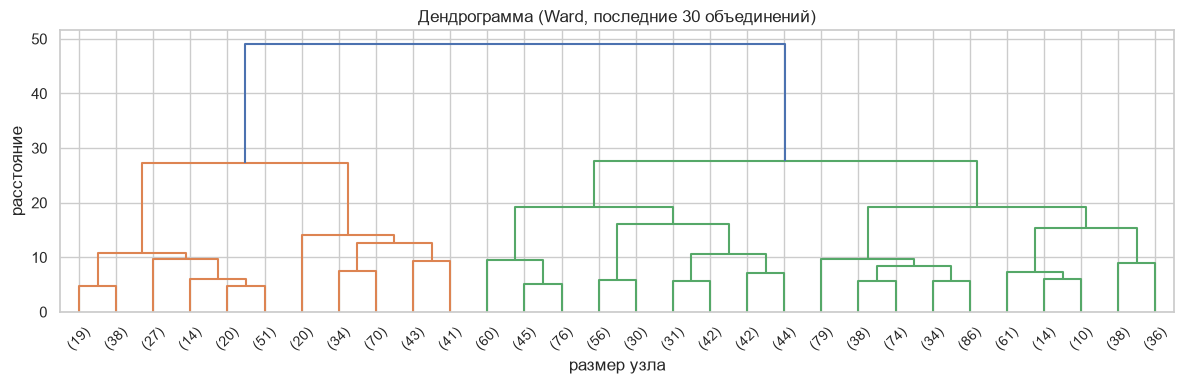

In [18]:
Z = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, color_threshold=0.7 * Z[:, 2].max())
ax.set(title="Дендрограмма (Ward, последние 30 объединений)", xlabel="размер узла", ylabel="расстояние")
plt.tight_layout(); plt.show()

In [19]:
for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 9):
        labels = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X)
        results.append(evaluate("Agglomerative", f"linkage={link}, k={k}", labels))

agg_res = pd.DataFrame([r for r in results if r["method"] == "Agglomerative"])
agg_res.drop(columns="method").round(3)

,params,n_clusters,noise_share,min_cluster_share,silhouette,davies_bouldin,calinski_harabasz,valid
0,"linkage=ward, k=2",2,0.0,0.296,0.332,1.272,585.728,True
1,"linkage=ward, k=3",3,0.0,0.296,0.182,1.645,450.317,True
2,"linkage=ward, k=4",4,0.0,0.133,0.202,1.433,443.307,True
3,"linkage=ward, k=5",5,0.0,0.125,0.179,1.415,403.987,True
4,"linkage=ward, k=6",6,0.0,0.125,0.195,1.378,394.421,True
5,"linkage=ward, k=7",7,0.0,0.068,0.191,1.344,379.084,True
6,"linkage=ward, k=8",8,0.0,0.058,0.203,1.240,372.210,True
7,"linkage=complete, k=2",2,0.0,0.213,0.296,1.224,445.965,True
8,"linkage=complete, k=3",3,0.0,0.213,0.174,1.698,377.713,True
9,"linkage=complete, k=4",4,0.0,0.016,0.155,1.512,278.772,False


Связи `average` и `single` дают вырожденные разбиения: один огромный кластер и несколько кластеров из 1–4 точек. Силуэт у них формально высокий, но такие варианты отсекаются ограничением на минимальный размер кластера.

### 6.3 DBSCAN

Диапазон `eps` выбираем по графику расстояний до k-го ближайшего соседа: «колено» графика — разумный порог плотности.

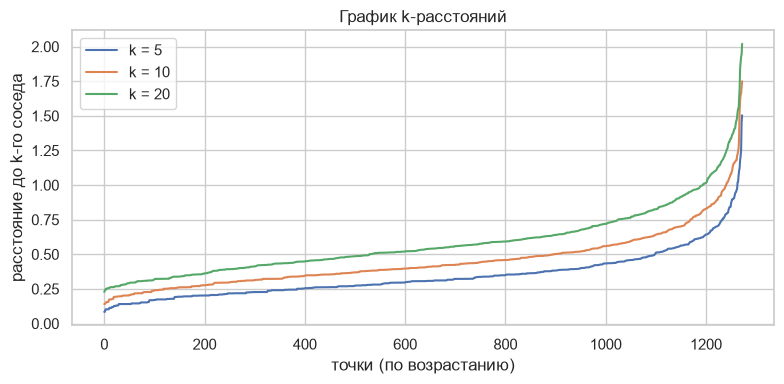

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
for k in [5, 10, 20]:
    dist, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)
    ax.plot(np.sort(dist[:, -1]), label=f"k = {k}")
ax.set(title="График k-расстояний", xlabel="точки (по возрастанию)", ylabel="расстояние до k-го соседа")
ax.legend(); plt.tight_layout(); plt.show()

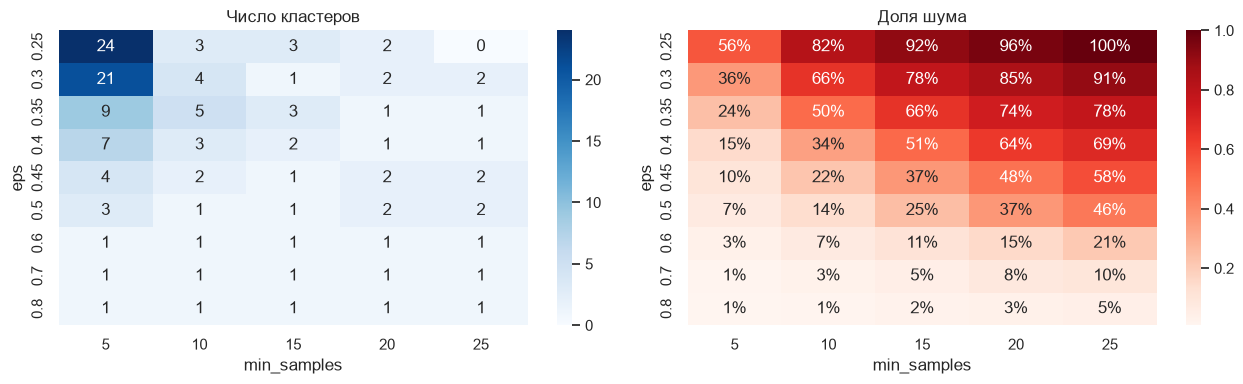

,params,n_clusters,noise_share,min_cluster_share,silhouette,davies_bouldin,calinski_harabasz,valid
0,"eps=0.25, min_samples=5",24,0.556,0.002,-0.055,0.805,37.486,False
1,"eps=0.25, min_samples=10",3,0.824,0.015,0.208,0.954,55.225,False
2,"eps=0.25, min_samples=15",3,0.915,0.009,0.348,0.831,142.780,False
3,"eps=0.25, min_samples=20",2,0.965,0.017,0.748,0.349,303.492,False
5,"eps=0.3, min_samples=5",21,0.363,0.004,-0.091,0.755,26.158,False
6,"eps=0.3, min_samples=10",4,0.658,0.007,-0.005,0.836,62.688,False
8,"eps=0.3, min_samples=20",2,0.849,0.016,0.221,1.051,28.353,False
9,"eps=0.3, min_samples=25",2,0.910,0.035,0.488,0.719,172.285,False
10,"eps=0.35, min_samples=5",9,0.242,0.004,-0.196,0.895,18.224,False
11,"eps=0.35, min_samples=10",5,0.504,0.007,0.176,0.720,48.676,False


In [21]:
for eps in [0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8]:
    for ms in [5, 10, 15, 20, 25]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        results.append(evaluate("DBSCAN", f"eps={eps}, min_samples={ms}", labels))

db_res = pd.DataFrame([r for r in results if r["method"] == "DBSCAN"])

pivot_n = db_res.assign(eps=db_res.params.str.extract(r"eps=([\d.]+)")[0].astype(float),
                        ms=db_res.params.str.extract(r"min_samples=(\d+)")[0].astype(int))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(pivot_n.pivot(index="eps", columns="ms", values="n_clusters"), annot=True, fmt="d",
            cmap="Blues", ax=axes[0])
axes[0].set(title="Число кластеров", xlabel="min_samples")
sns.heatmap(pivot_n.pivot(index="eps", columns="ms", values="noise_share"), annot=True, fmt=".0%",
            cmap="Reds", ax=axes[1])
axes[1].set(title="Доля шума", xlabel="min_samples")
plt.tight_layout(); plt.show()
db_res[db_res.n_clusters >= 2].drop(columns="method").round(3)

DBSCAN показывает важное свойство данных: при малом `eps` большая часть точек объявляется шумом, а при чуть большем — все точки сливаются в **один** кластер. Устойчивых, разделённых областями низкой плотности групп в пространстве трёх признаков нет — образцы образуют одно непрерывное «облако». Во всех конфигурациях с ≥2 кластерами самый маленький кластер занимает менее 4 % выборки: при доле шума < 15 % от основного облака отделяются лишь «островки» из нескольких точек, а более крупные группы появляются только когда шумом объявлено 22–97 % данных.

## 7. Сравнение вариантов по метрике

In [22]:
res = pd.DataFrame(results)
print(f"Всего обучено конфигураций: {len(res)}, допустимых: {res.valid.sum()}")

best_per_method = (res[res.valid].sort_values("silhouette", ascending=False)
                   .groupby("method", as_index=False).head(1))
# если у метода нет допустимых вариантов, показываем его разбиение с >=2 кластерами и наименьшей долей шума
for m in ["K-Means", "Agglomerative", "DBSCAN"]:
    if m not in set(best_per_method.method):
        cand = res[(res.method == m) & (res.n_clusters >= 2)].sort_values(["noise_share", "silhouette"], ascending=[True, False]).head(1)
        best_per_method = pd.concat([best_per_method, cand])
best_per_method = best_per_method.set_index("method")
best_per_method.round(3)

Всего обучено конфигураций: 91, допустимых: 26


,params,n_clusters,noise_share,min_cluster_share,silhouette,davies_bouldin,calinski_harabasz,valid
method,,,,,,,,
K-Means,"k=2, init=k-means++",2,0.000,0.405,0.339,1.220,703.609,True
Agglomerative,"linkage=ward, k=2",2,0.000,0.296,0.332,1.272,585.728,True
DBSCAN,"eps=0.5, min_samples=5",3,0.072,0.004,0.092,0.753,14.402,False


In [23]:
top = res[res.valid].sort_values("silhouette", ascending=False).head(10)
top.round(3)

,method,params,n_clusters,noise_share,min_cluster_share,silhouette,davies_bouldin,calinski_harabasz,valid
0,K-Means,"k=2, init=k-means++",2,0.0,0.405,0.339,1.220,703.609,True
9,K-Means,"k=2, init=random",2,0.0,0.405,0.339,1.220,703.609,True
18,Agglomerative,"linkage=ward, k=2",2,0.0,0.296,0.332,1.272,585.728,True
10,K-Means,"k=3, init=random",3,0.0,0.218,0.324,1.203,584.240,True
1,K-Means,"k=3, init=k-means++",3,0.0,0.219,0.323,1.204,584.246,True
25,Agglomerative,"linkage=complete, k=2",2,0.0,0.213,0.296,1.224,445.965,True
3,K-Means,"k=5, init=k-means++",5,0.0,0.125,0.272,1.125,548.128,True
12,K-Means,"k=5, init=random",5,0.0,0.119,0.271,1.136,548.217,True
11,K-Means,"k=4, init=random",4,0.0,0.192,0.269,1.187,587.517,True
2,K-Means,"k=4, init=k-means++",4,0.0,0.197,0.267,1.201,587.425,True


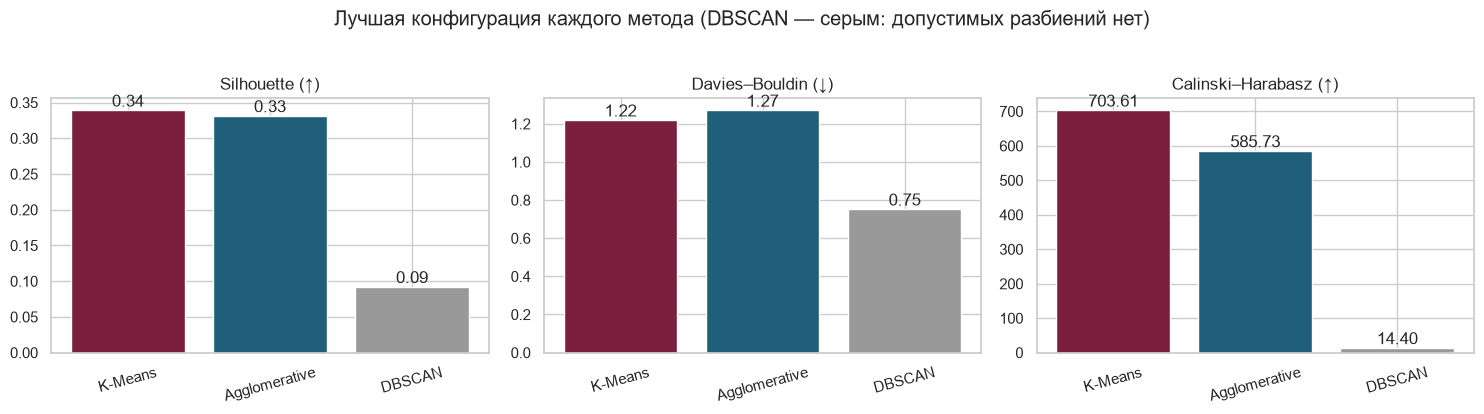

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#7a1f3d", "#1f5f7a", "#999999"]
for ax, metric, title in zip(axes,
                             ["silhouette", "davies_bouldin", "calinski_harabasz"],
                             ["Silhouette (↑)", "Davies–Bouldin (↓)", "Calinski–Harabasz (↑)"]):
    vals = best_per_method[metric]
    bars = ax.bar(best_per_method.index, vals, color=colors[:len(vals)])
    ax.bar_label(bars, fmt="%.2f")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=15)
plt.suptitle("Лучшая конфигурация каждого метода (DBSCAN — серым: допустимых разбиений нет)", y=1.03)
plt.tight_layout(); plt.show()

In [25]:
best = res[res.valid].sort_values("silhouette", ascending=False).iloc[0]
print(f"Лучшая модель: {best.method} ({best.params})")
print(f"silhouette = {best.silhouette:.3f}, Davies–Bouldin = {best.davies_bouldin:.3f}, "
      f"Calinski–Harabasz = {best.calinski_harabasz:.0f}")

Лучшая модель: K-Means (k=2, init=k-means++)
silhouette = 0.339, Davies–Bouldin = 1.220, Calinski–Harabasz = 704


**Итог сравнения**

* Лучший силуэт среди допустимых разбиений — у **K-Means с k = 2** (≈ 0.34); иерархическая кластеризация Ward с k = 2 почти так же хороша (≈ 0.33) и выделяет практически ту же структуру — это подтверждает устойчивость найденного разбиения.
* С ростом k силуэт падает, при k = 3 у K-Means он ещё близок (≈ 0.32), дальше — заметно ниже.
* DBSCAN не нашёл допустимого разбиения: плотностной структуры с несколькими кластерами в данных нет.
* Значения силуэта ≈ 0.3 означают **слабую, но реальную** структуру: сегменты есть, но границы между ними размыты.

## 8. Кластеризация лучшей моделью и сопоставление с качеством вина

In [26]:
BEST_K = int(best.params.split(",")[0].split("=")[1])
best_model = KMeans(n_clusters=BEST_K, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(X)

# упорядочим номера кластеров по среднему содержанию алкоголя, чтобы нумерация была осмысленной
order = df.groupby(best_model.labels_)["alcohol"].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
df["cluster"] = pd.Series(best_model.labels_).map(relabel)

print("Размеры кластеров:")
print(df["cluster"].value_counts().sort_index().to_string())

Размеры кластеров:
cluster
0    758
1    515


### 8.1 Визуализация кластеров

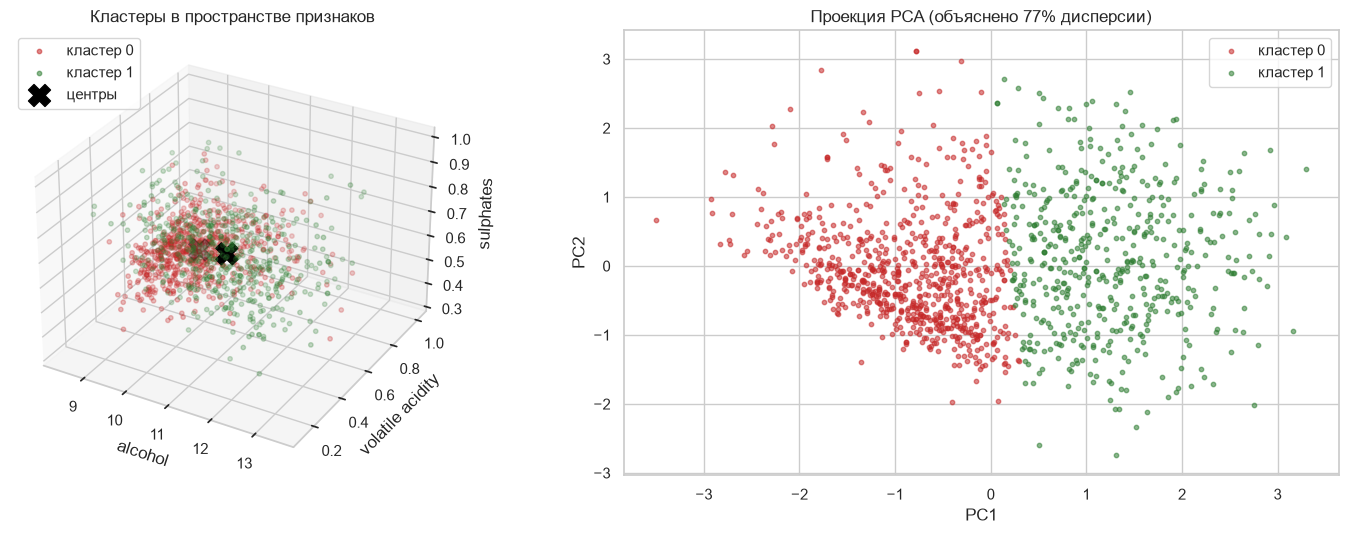

In [27]:
palette = ["#c62828", "#2e7d32", "#1565c0", "#f9a825", "#6a1b9a"]
centers = scaler.inverse_transform(best_model.cluster_centers_)[order]

fig = plt.figure(figsize=(15, 5.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for c in sorted(df.cluster.unique()):
    part = df[df.cluster == c]
    ax.scatter(part[FEATURES[0]], part[FEATURES[1]], part[FEATURES[2]], s=10, alpha=.55,
               color=palette[c], label=f"кластер {c}")
ax.scatter(centers[:, 0], centers[:, 1], centers[:, 2], s=250, c="black", marker="X", label="центры")
ax.set(xlabel=FEATURES[0], ylabel=FEATURES[1], zlabel=FEATURES[2], title="Кластеры в пространстве признаков")
ax.legend(loc="upper left")

ax2 = fig.add_subplot(1, 2, 2)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
for c in sorted(df.cluster.unique()):
    m = df.cluster.values == c
    ax2.scatter(P[m, 0], P[m, 1], s=10, alpha=.55, color=palette[c], label=f"кластер {c}")
ax2.set(title=f"Проекция PCA (объяснено {pca.explained_variance_ratio_.sum():.0%} дисперсии)",
        xlabel="PC1", ylabel="PC2")
ax2.legend()
plt.tight_layout(); plt.show()

### 8.2 Профили кластеров

In [28]:
profile = df.groupby("cluster")[FEATURES + ["quality"]].agg(["mean", "std"]).round(2)
profile.insert(0, ("n", ""), df.cluster.value_counts().sort_index())
profile

n alcohol       volatile acidity       sulphates       quality  \
                mean   std             mean   std      mean   std    mean   
cluster                                                                     
0        758    9.89  0.69             0.60  0.15      0.58  0.08    5.31   
1        515   11.20  0.98             0.41  0.12      0.72  0.11    6.10   

               
          std  
cluster        
0        0.64  
1        0.79

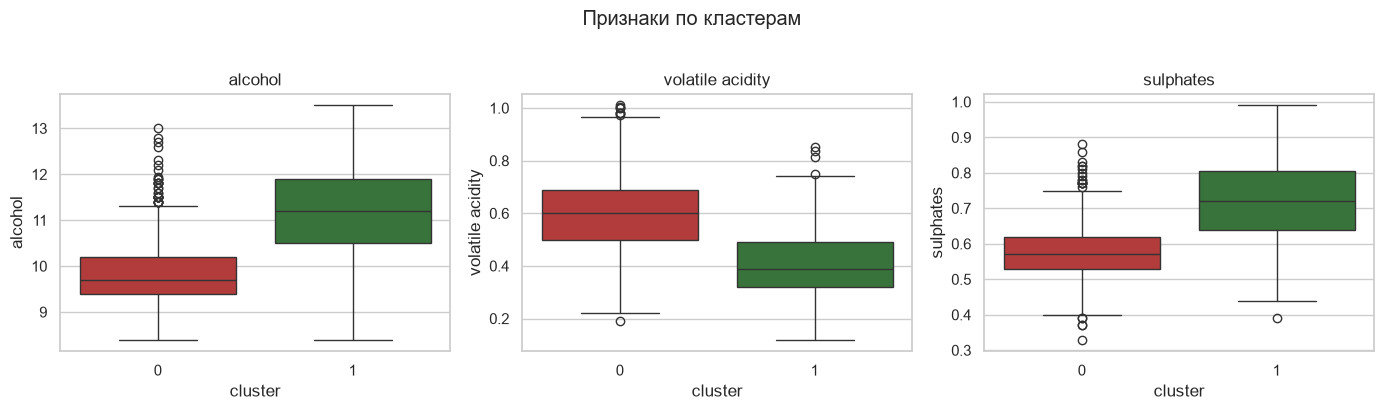

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=df, x="cluster", y=col, palette=palette[:BEST_K], ax=ax)
    ax.set_title(col)
plt.suptitle("Признаки по кластерам", y=1.02)
plt.tight_layout(); plt.show()

### 8.3 Кластеры и оценка качества

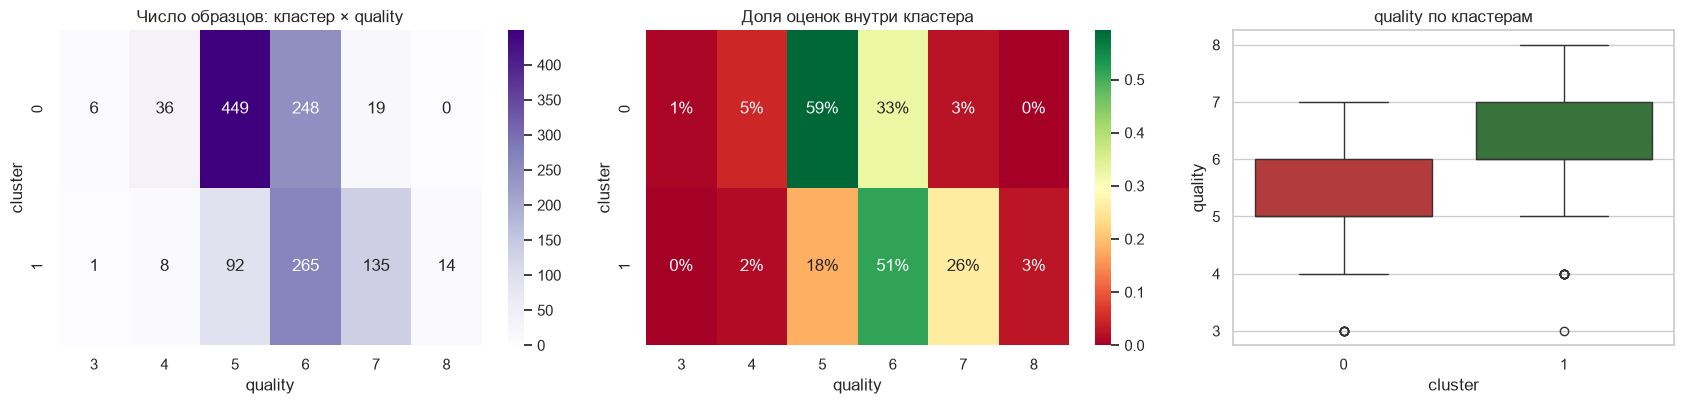

quality,3,4,5,6,7,8
cluster,,,,,,
0,6,36,449,248,19,0
1,1,8,92,265,135,14


In [30]:
ct = pd.crosstab(df.cluster, df.quality)
ct_norm = pd.crosstab(df.cluster, df.quality, normalize="index")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
sns.heatmap(ct, annot=True, fmt="d", cmap="Purples", ax=axes[0])
axes[0].set(title="Число образцов: кластер × quality")
sns.heatmap(ct_norm, annot=True, fmt=".0%", cmap="RdYlGn", ax=axes[1])
axes[1].set(title="Доля оценок внутри кластера")
sns.boxplot(data=df, x="cluster", y="quality", palette=palette[:BEST_K], ax=axes[2])
axes[2].set(title="quality по кластерам")
plt.tight_layout(); plt.show()
ct

In [31]:
df["quality_group"] = pd.cut(df.quality, bins=[0, 5, 6, 10], labels=["низкое (3–5)", "среднее (6)", "высокое (7–8)"])
summary = pd.DataFrame({
    "n": df.cluster.value_counts().sort_index(),
    "средняя quality": df.groupby("cluster").quality.mean().round(2),
    "медиана quality": df.groupby("cluster").quality.median(),
})
summary = summary.join((pd.crosstab(df.cluster, df.quality_group, normalize="index") * 100).round(1).add_suffix(", %"))
summary

,n,средняя quality,медиана quality,"низкое (3–5), %","среднее (6), %","высокое (7–8), %"
cluster,,,,,,
0,758,5.31,5.0,64.8,32.7,2.5
1,515,6.10,6.0,19.6,51.5,28.9


In [32]:
ari = adjusted_rand_score(df.quality, df.cluster)
nmi = normalized_mutual_info_score(df.quality, df.cluster)
ari_bin = adjusted_rand_score(df.quality >= 6, df.cluster)
print(f"ARI (кластеры vs quality 3–8):          {ari:.3f}")
print(f"NMI (кластеры vs quality 3–8):          {nmi:.3f}")
print(f"ARI (кластеры vs quality >= 6 / < 6):    {ari_bin:.3f}")

# для сравнения: такая же сегментация на 3 кластера
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
print(f"\nK-Means k=3 для сравнения: silhouette = {silhouette_score(X, km3):.3f}, "
      f"ARI = {adjusted_rand_score(df.quality, km3):.3f}")
df.assign(k3=km3).groupby("k3")[FEATURES + ["quality"]].mean().sort_values("quality").round(2)

ARI (кластеры vs quality 3–8):          0.147
NMI (кластеры vs quality 3–8):          0.149
ARI (кластеры vs quality >= 6 / < 6):    0.177

K-Means k=3 для сравнения: silhouette = 0.323, ARI = 0.157


,alcohol,volatile acidity,sulphates,quality
k3,,,,
1,9.80,0.60,0.57,5.27
0,10.44,0.40,0.79,5.96
2,11.83,0.47,0.64,6.15


## Выводы

1. **Данные.** 1599 образцов красного вина, 11 физико-химических признаков, пропусков нет; после удаления 240 дубликатов и 86 выбросов (по 1.5·IQR для выбранных признаков) осталось 1273 образца. Признаки разномасштабны и скошены, поэтому применены очистка и стандартизация.
2. **Признаки для сегментации:** `alcohol`, `volatile acidity`, `sulphates` — сильнее всего связаны с качеством и слабо коррелируют друг с другом.
3. **Методы и метрика.** Сравнивались K-Means (итеративный), агломеративная кластеризация (иерархический) и DBSCAN (плотностной), всего 91 конфигурация. Модель выбиралась по коэффициенту силуэта с ограничениями против вырожденных разбиений; Дэвис–Болдин и Калински–Харабаз использовались как контрольные.
4. **Лучшая модель — K-Means, k = 2** (silhouette ≈ 0.34). Ward с k = 2 даёт почти то же самое, DBSCAN допустимого разбиения не нашёл — в пространстве этих признаков нет областей, разделённых низкой плотностью, образцы образуют одно непрерывное облако. Поэтому сегментация здесь — это разделение непрерывного спектра, а не поиск «естественных» изолированных групп.
5. **Сопоставление с качеством.** Кластеры получились содержательными:
   * **кластер 0** — менее крепкие вина (≈ 9.9 % алкоголя) с повышенной летучей кислотностью (≈ 0.60 г/л) и меньшим содержанием сульфатов; средняя оценка ≈ 5.3, около ⅔ образцов имеют оценку 3–5;
   * **кластер 1** — более крепкие (≈ 11.2 %), с низкой летучей кислотностью (≈ 0.41) и бо́льшим содержанием сульфатов; средняя оценка ≈ 6.1, сюда попали 89 % всех вин с оценкой 7–8.
6. **Ограничение.** Внешнее согласие с оценкой качества невысокое (ARI ≈ 0.15, NMI ≈ 0.15): химия по трём признакам задаёт **тенденцию** («крепкое, без уксусного тона и с сульфатами → выше оценка»), но не определяет оценку однозначно — в обоих кластерах много вин с оценкой 5–6. Это ожидаемо: оценка — субъективная медиана дегустаторов, а классы сильно несбалансированы. Кластеризация полезна как грубая сегментация партий «вероятно рядовое / вероятно хорошее» и как подсказка, какие параметры технологу контролировать в первую очередь.